# Task 3: Cold-Target Generalisation

Task 2's CF cannot generalise an unseen target: its
prediction falls back to the ligand's mean and is identical for every target.

**Approach:** Find neighbours by **amino-acid sequence similarity** instead of by
co-measurement, so an unseen target still has usable neighbours.

In [116]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

PROJECT = Path.cwd().resolve()
while not (PROJECT / "src" / "common.py").exists() and PROJECT != PROJECT.parent:
    PROJECT = PROJECT.parent
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))

from common import SEED, ConstantModel, Frame, NeighbourhoodCF, evaluate, mse

os.makedirs("figures", exist_ok=True)
DATASETS = ["DAVIS", "KIBA"]


def train_targets(frame):
    """Column indices of the targets that have training measurements."""
    return np.unique(frame.xy("train")[1])

## 1. The cold-target split

Task 3 focuses on targets, so the targets are split instead: a target goes to train, val or test
as a whole, taking all its measurements with it.

In [117]:
def make_cold_split(df, seed=SEED, fractions=(0.70, 0.15, 0.15)):
    targets = np.array(sorted(set(df["target_id"])))
    order = np.random.default_rng(seed).permutation(len(targets))
    n_train = int(fractions[0] * len(targets))
    n_val = int(fractions[1] * len(targets))
    assignment = {}
    for part, idx in [("train", order[:n_train]), ("val", order[n_train:n_train + n_val]),
                      ("test", order[n_train + n_val:])]:
        assignment.update({t: part for t in targets[idx]})
    return df.assign(split=df["target_id"].map(assignment))


clean, cold, frames = {}, {}, {}
for name in DATASETS:
    clean[name] = pd.read_csv(f"data/processed/{name.lower()}_clean.csv",
                              dtype={"ligand_id": str, "target_id": str})
    cold[name] = make_cold_split(clean[name][["ligand_id", "target_id", "score"]])
    cold[name].to_csv(f"data/processed/{name.lower()}_cold_split.csv", index=False)
    frames[name] = Frame(cold[name])

rows = []
for name, df in cold.items():
    seen_in_train = set(df.loc[df["split"] == "train", "target_id"])
    seen_ligands = set(df.loc[df["split"] == "train", "ligand_id"])
    for part in ["train", "val", "test"]:
        sub = df[df["split"] == part]
        rows.append({"dataset": name, "split": part, "pairs": len(sub),
                     "targets": sub["target_id"].nunique(),
                     "ligands": sub["ligand_id"].nunique(),
                     "targets also in train": len(set(sub["target_id"]) & seen_in_train),
                     "ligands also in train": len(set(sub["ligand_id"]) & seen_ligands)})
pd.DataFrame(rows).set_index(["dataset", "split"])

pairs  targets  ligands  targets also in train  \
dataset split                                                   
DAVIS   train  18020      265       68                    265   
        val     3808       56       68                      0   
        test    3944       58       68                      0   
KIBA    train  80374      160     2068                    160   
        val    16800       34     1831                      0   
        test   20483       35     1855                      0   

               ligands also in train  
dataset split                         
DAVIS   train                     68  
        val                       68  
        test                      68  
KIBA    train                   2068  
        val                     1831  
        test                    1855

In [118]:
for name, frame in frames.items():
    _, test_cols, _ = frame.xy("test")
    per_target = np.isfinite(frame.R)[:, np.unique(test_cols)].sum(axis=0)
    print(f"{name}: training measurements per test target - "
          f"min {per_target.min()}, max {per_target.max()}")

DAVIS: training measurements per test target - min 0, max 0
KIBA: training measurements per test target - min 0, max 0


## 2. Task 2 CF Limitations

Ranking is reported two ways: **per ligand** (given a drug, rank its candidate targets) and **per target** (given a new protein, rank candidate drugs)

In [119]:
TASK2_PARAMS = {"DAVIS": {"axis": "target", "k": 10, "shrinkage": 10.0},
                "KIBA": {"axis": "ligand", "k": 5, "shrinkage": 25.0}}

models = {name: {"ligand mean": ConstantModel("ligand").fit(frame),
                 "CF neighbourhood (Task 2)": NeighbourhoodCF(**TASK2_PARAMS[name]).fit(frame)}
          for name, frame in frames.items()}

results = pd.DataFrame([{"dataset": name, "model": label, **evaluate(model, frames[name])}
                        for name, group in models.items() for label, model in group.items()]
                       ).set_index(["dataset", "model"])
results[["MSE", "CI", "Hit@1 (per ligand)", "Hit@1 random (per ligand)",
         "Hit@1 (per target)"]].round(4)

MSE      CI  Hit@1 (per ligand)  \
dataset model                                                           
DAVIS   ligand mean                0.4597  0.7842              0.0441   
        CF neighbourhood (Task 2)  0.4601  0.7842              0.0441   
KIBA    ligand mean                0.3944  0.7157              0.0766   
        CF neighbourhood (Task 2)  0.4379  0.7061              0.0766   

                                   Hit@1 random (per ligand)  \
dataset model                                                  
DAVIS   ligand mean                                   0.0172   
        CF neighbourhood (Task 2)                     0.0172   
KIBA    ligand mean                                   0.0742   
        CF neighbourhood (Task 2)                     0.0742   

                                   Hit@1 (per target)  
dataset model                                          
DAVIS   ligand mean                            0.2759  
        CF neighbourhood (Task 2)              0.2759  
KIBA    ligand mean                            0.1714  
        CF neighbourhood (Task 2)              0.2000

In [120]:
checks = []
for name, frame in frames.items():
    cf = models[name]["CF neighbourhood (Task 2)"]
    rows, cols, y_true = frame.xy("test")
    y_pred = cf.predict(rows, cols)
    per_ligand = pd.DataFrame({"lig": rows, "true": y_true, "pred": y_pred}).groupby("lig")
    checks.append({
        "dataset": name,
        "train fallback": cf.fallback_rate(frame, "train"),
        "test fallback": cf.fallback_rate(frame, "test"),
        "true spread across a ligand's unseen targets": per_ligand["true"].std().mean(),
        "predicted spread": per_ligand["pred"].std().mean(),
    })
pd.DataFrame(checks).set_index("dataset").round(4)

,train fallback,test fallback,true spread across a ligand's unseen targets,predicted spread
dataset,,,,
DAVIS,0.0,1.0,0.5934,0.0
KIBA,0.0,1.0,0.4776,0.0


Every test prediction is a fallback (1.00 vs 0.00 on training data). The true scores vary across a ligand's unseen targets while the predictions have spread exactly 0. 

Hit@1 per ligand for ligand mean and CF are identical as the target ranking is just by order of the data, not an actual ranking since the CF falls back to the same values.

## 3. Target features from the amino acid sequence

Each amino-acid sequence is split into overlapping windows of 3 residues. These are weighted so that more common fragments found are weighted less, and normalised so that long and short proteins are comparable, then compressed into a short vector. Two targets are compared by the cosine between those vectors(how closely related the sequence of the targets are).

In [121]:
def build_features(frame, texts, ngram=(3, 3), n_components=64):
    """Rows aligned to frame.targets, L2-normalised so a dot product is a cosine."""
    train_ids = frame.targets[train_targets(frame)]
    vectorizer = TfidfVectorizer(analyzer="char", ngram_range=ngram, lowercase=False)
    fitted = vectorizer.fit_transform(texts.loc[train_ids].to_numpy())
    svd = TruncatedSVD(n_components=n_components, random_state=SEED).fit(fitted)
    features = svd.transform(vectorizer.transform(texts.loc[frame.targets].to_numpy()))
    return features / np.maximum(np.linalg.norm(features, axis=1, keepdims=True), 1e-12)


sequences, target_features = {}, {}
for name, frame in frames.items():
    sequences[name] = (clean[name].drop_duplicates("target_id")
                       .set_index("target_id")["sequence"])
    target_features[name] = build_features(frame, sequences[name])
    lengths = sequences[name].str.len()
    print(f"{name}: {target_features[name].shape[0]} targets x "
          f"{target_features[name].shape[1]} features; sequence length "
          f"{lengths.min()}-{lengths.max()} residues")

DAVIS: 379 targets x 64 features; sequence length 244-2549 residues
KIBA: 229 targets x 64 features; sequence length 215-4128 residues


### Can we use similarity of drug sequences to determine similar target behaviour?

For every pair of training targets, compare their sequence cosine against the correlation of
their binding profiles across the ligands measured on both. Profiles are centred by ligand
first, so drugs which are indiscriminate/have random binding patterns do not make every pair look alike.

In [122]:
MIN_OVERLAP = {"DAVIS": 10, "KIBA": 20}
BANDS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

pairs, summary = {}, []
for name, frame in frames.items():
    train_cols = train_targets(frame)
    cosine = target_features[name][train_cols] @ target_features[name][train_cols].T
    centred = frame.R - np.nanmean(frame.R, axis=1, keepdims=True)
    correlation = (pd.DataFrame(centred, columns=frame.targets)[frame.targets[train_cols]]
                   .corr(min_periods=MIN_OVERLAP[name]).to_numpy())
    upper = np.triu_indices(len(train_cols), k=1)
    table = pd.DataFrame({"cosine": cosine[upper],
                          "profile corr": correlation[upper]}).dropna()
    pairs[name] = table
    stats = table.groupby(pd.cut(table["cosine"], BANDS, include_lowest=True),
                          observed=True)["profile corr"].agg(["count", "mean"])
    stats.columns = pd.MultiIndex.from_product([[name], ["pairs", "mean corr"]])
    summary.append(stats)
    print(f"{name}: Spearman rho over all pairs = "
          f"{spearmanr(table['cosine'], table['profile corr']).statistic:.3f}")

pd.concat(summary, axis=1).rename_axis("sequence cosine band").round(3)

DAVIS: Spearman rho over all pairs = 0.048
KIBA: Spearman rho over all pairs = 0.081


DAVIS            KIBA          
                      pairs mean corr pairs mean corr
sequence cosine band                                 
(-0.001, 0.2]         14147    -0.012  4709    -0.026
(0.2, 0.4]            16780     0.000  1736     0.010
(0.4, 0.6]             3524     0.019   172     0.127
(0.6, 0.8]              348     0.194    21     0.326
(0.8, 1.0]              118     0.717    41     0.712

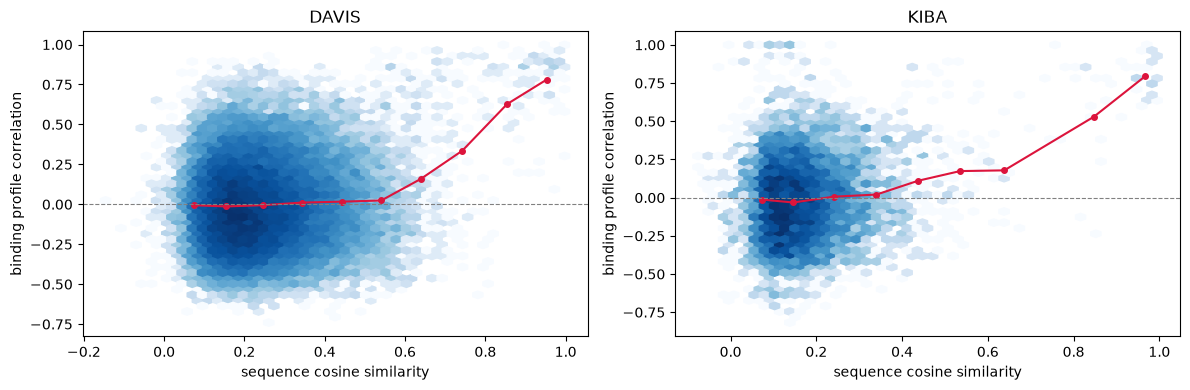

In [123]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, table) in zip(axes, pairs.items()):
    ax.hexbin(table["cosine"], table["profile corr"], gridsize=45,
              cmap="Blues", bins="log", mincnt=1)
    band = pd.cut(table["cosine"], np.arange(0.0, 1.0001, 0.1), include_lowest=True)
    centres = table.groupby(band, observed=True).agg(
        x=("cosine", "mean"), y=("profile corr", "mean"), n=("cosine", "size"))
    centres = centres[centres["n"] >= 10]
    ax.plot(centres["x"], centres["y"], "-o", color="crimson", markersize=4)
    ax.axhline(0.0, color="grey", linewidth=0.8, linestyle="--")
    ax.set_xlabel("sequence cosine similarity")
    ax.set_ylabel("binding profile correlation")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/task3_sequence_signal.png", dpi=200)
plt.show()

In [124]:
frame = frames["DAVIS"]
train_cols, test_cols = train_targets(frame), np.unique(frame.xy("test")[1])
similarity = target_features["DAVIS"][test_cols] @ target_features["DAVIS"][train_cols].T
pd.DataFrame([
    {"cold test target": frame.targets[test_cols[i]],
     "nearest training targets": ", ".join(
         f"{frame.targets[train_cols[j]]} ({similarity[i, j]:.2f})"
         for j in np.argsort(-similarity[i])[:3])}
    for i in np.argsort(-similarity.max(axis=1))[:8]]).rename_axis(
    "the 8 cold targets with the closest training relative")

,cold test target,nearest training targets
the 8 cold targets with the closest training relative,,
0,PKAC-beta,"PKAC-alpha (0.99), PRKX (0.72), PRKG1 (0.61)"
1,JNK2,"JNK3 (0.98), JNK1 (0.98), LRRK2 (0.36)"
2,PAK2,"PAK1 (0.98), PAK3 (0.98), ZAK (0.44)"
3,CAMK2G,"CAMK2D (0.98), CAMK2A (0.97), CASK (0.49)"
4,RSK4(KinDom.1-N-terminal),"RSK1(KinDom.1-N-terminal) (0.97), RSK2(KinDom...."
5,CSNK1G3,"CSNK1G2 (0.97), CSNK1A1 (0.70), CSNK1D (0.69)"
6,AURKC,"AURKB (0.96), AURKA (0.92), PIK3C2B (0.48)"
7,EPHA5,"EPHA7 (0.96), EPHA4 (0.96), EPHA3 (0.95)"


The relationship varies across different ranges. Mean profile correlation is near zero below cosine
0.4 but reaches about 0.72 above 0.8, so only close relatives behave alike. The Spearman
correlation over all pairs is low (0.05-0.08) precisely because the large mass of distant,
uninformative pairs drowns out the informative tail.

Where a close relative exists, it is the biologically right one (`PKAC-beta` to
`PKAC-alpha`, `JNK2` to `JNK3`, `CAMK2G` to `CAMK2D`), so the representation captures genuine
protein relationships.

This suggests that we shoould also take the top few closely related targets as an indicator of the target's behaviour.

## 4. The sequence-neighbour recommender

To predict how ligand **L** binds an unseen target **T**:

1. rank the training targets by sequence cosine similarity to T;
2. keep the **k** most similar ones that L was actually measured against;
3. predict L's own baseline plus the similarity-weighted average of L's deviations there.

```
predicted score  =  the ligand's baseline level
                 +  weighted average of that ligand's deviations
                    on the k most sequence-similar known targets
```

The only hyperparameter is k, chosen on the cold
validation targets

In [125]:
class SequenceKNN:
    """Ligand baseline plus a similarity-weighted average over the k most
    sequence-similar training targets that the ligand was measured against."""

    def __init__(self, k=10, reg=5.0):
        self.k, self.reg = k, reg

    def fit(self, frame, features):
        self.features = features
        rows, cols, vals = frame.xy("train")
        self.mu = float(vals.mean())
        n_ligands = frame.R.shape[0]
        totals = np.bincount(rows, weights=vals - self.mu, minlength=n_ligands)
        counts = np.bincount(rows, minlength=n_ligands)
        self.b_lig = totals / (counts + self.reg)
        self.train_cols = train_targets(frame)
        block = frame.R[:, self.train_cols]
        self.observed = np.isfinite(block)
        self.residuals = np.where(self.observed, block - (self.mu + self.b_lig[:, None]), 0.0)
        return self

    def predict(self, rows, cols):
        predictions = self.mu + self.b_lig[rows]
        similarity = self.features[cols] @ self.features[self.train_cols].T
        for target in np.unique(cols):
            picked = np.flatnonzero(cols == target)
            s = np.clip(similarity[picked[0]], 0, None)
            order = np.argsort(-s)
            neighbours = self.observed[:, order]
            keep = neighbours & (np.cumsum(neighbours, axis=1) <= self.k)
            weights = keep * s[order]
            total = weights.sum(axis=1)
            correction = np.where(total > 0,
                                  (weights * self.residuals[:, order]).sum(axis=1)
                                  / np.maximum(total, 1e-12), 0.0)
            predictions[picked] += correction[rows[picked]]
        return predictions

In [126]:
K_GRID = [1, 3, 5, 10, 20, 40, 60]

search, best_k = [], {}
for name, frame in frames.items():
    val_rows, val_cols, val_true = frame.xy("val")
    for k in K_GRID:
        model = SequenceKNN(k).fit(frame, target_features[name])
        search.append({"dataset": name, "k": k,
                       "val MSE": mse(val_true, model.predict(val_rows, val_cols))})
    scores = pd.DataFrame(search)
    scores = scores[scores["dataset"] == name]
    best_k[name] = int(scores.loc[scores["val MSE"].idxmin(), "k"])
    print(f"{name}: best k = {best_k[name]}")

pd.DataFrame(search).pivot(index="k", columns="dataset", values="val MSE").round(4)

DAVIS: best k = 10
KIBA: best k = 40


dataset,DAVIS,KIBA
k,,
1,0.5658,0.6061
3,0.3863,0.4513
5,0.3671,0.4442
10,0.3482,0.4452
20,0.3668,0.4365
40,0.3769,0.4346
60,0.3860,0.4356


In [127]:
for name, frame in frames.items():
    models[name]["sequence kNN"] = SequenceKNN(best_k[name]).fit(frame, target_features[name])

results = pd.DataFrame([{"dataset": name, "model": label, **evaluate(model, frames[name])}
                        for name, group in models.items() for label, model in group.items()]
                       ).set_index(["dataset", "model"])
results[["MSE", "CI", "Hit@1 (per ligand)", "Hit@5 (per ligand)",
         "Hit@1 (per target)", "Hit@5 (per target)"]].round(4)

MSE      CI  Hit@1 (per ligand)  \
dataset model                                                           
DAVIS   ligand mean                0.4597  0.7842              0.0441   
        CF neighbourhood (Task 2)  0.4601  0.7842              0.0441   
        sequence kNN               0.3697  0.8124              0.3235   
KIBA    ligand mean                0.3944  0.7157              0.0766   
        CF neighbourhood (Task 2)  0.4379  0.7061              0.0766   
        sequence kNN               0.3824  0.7256              0.2601   

                                   Hit@5 (per ligand)  Hit@1 (per target)  \
dataset model                                                               
DAVIS   ligand mean                            0.1176              0.2759   
        CF neighbourhood (Task 2)              0.1176              0.2759   
        sequence kNN                           0.5441              0.3793   
KIBA    ligand mean                            0.3782              0.1714   
        CF neighbourhood (Task 2)              0.3782              0.2000   
        sequence kNN                           0.6513              0.2571   

                                   Hit@5 (per target)  
dataset model                                          
DAVIS   ligand mean                            0.4828  
        CF neighbourhood (Task 2)              0.4828  
        sequence kNN                           0.6724  
KIBA    ligand mean                            0.4286  
        CF neighbourhood (Task 2)              0.4571  
        sequence kNN                           0.4571

In [128]:
checks = []
for name, frame in frames.items():
    rows, cols, _ = frame.xy("test")
    predicted = models[name]["sequence kNN"].predict(rows, cols)
    spread = pd.DataFrame({"lig": rows, "pred": predicted}).groupby("lig")["pred"].std()
    cf_predicted = models[name]["CF neighbourhood (Task 2)"].predict(rows, cols)
    cf_spread = pd.DataFrame({"lig": rows, "pred": cf_predicted}).groupby("lig")["pred"].std()
    checks.append({"dataset": name, "predicted spread (Task 2 CF)": cf_spread.mean(),
                   "predicted spread (sequence kNN)": spread.mean()})
pd.DataFrame(checks).set_index("dataset").round(4)

,predicted spread (Task 2 CF),predicted spread (sequence kNN)
dataset,,
DAVIS,0.0,0.2415
KIBA,0.0,0.0593


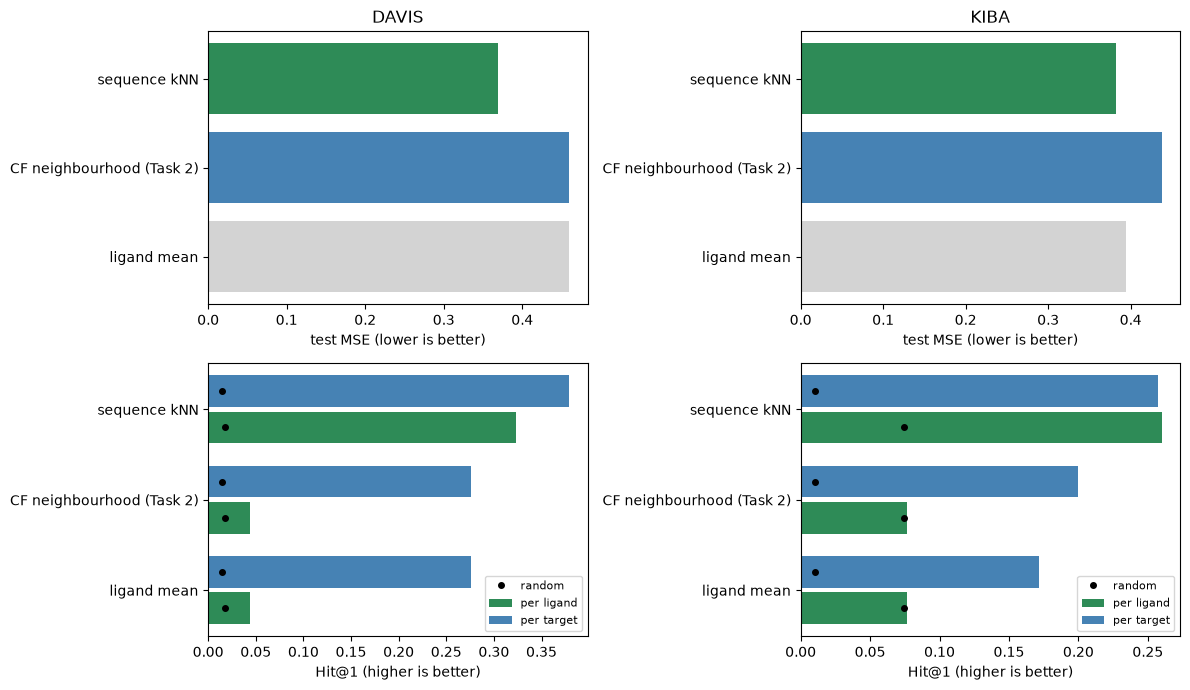

In [129]:
order = ["ligand mean", "CF neighbourhood (Task 2)", "sequence kNN"]
colours = ["lightgrey", "steelblue", "seagreen"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, name in enumerate(DATASETS):
    sub = results.loc[name].loc[order]
    axes[0, col].barh(order, sub["MSE"], color=colours)
    axes[0, col].set_xlabel("test MSE (lower is better)")
    axes[0, col].set_title(name)

    y = np.arange(len(order))
    axes[1, col].barh(y - 0.2, sub["Hit@1 (per ligand)"], height=0.35,
                      color="seagreen", label="per ligand")
    axes[1, col].barh(y + 0.2, sub["Hit@1 (per target)"], height=0.35,
                      color="steelblue", label="per target")
    axes[1, col].plot(sub["Hit@1 random (per ligand)"], y - 0.2, "ko", markersize=4)
    axes[1, col].plot(sub["Hit@1 random (per target)"], y + 0.2, "ko", markersize=4,
                      label="random")
    axes[1, col].set_yticks(y)
    axes[1, col].set_yticklabels(order)
    axes[1, col].set_xlabel("Hit@1 (higher is better)")
    axes[1, col].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/task3_model_comparison.png", dpi=200)
plt.show()

### Results

The predicted spread of values across a ligand's unseen targets is no longer 0, all the predictions do not fallback to the same value anymore. The model is able to generate rankings amongst unseen targets.

The scores reveal that the test MSE and Hit@1 scores have improved across both DAVIES and KIBA datasets. The per ligand improvement is more significant, as the sequence kNN has addressed the issue of differentiating between the cold targets based on their sequence, allowing them to be ranked more accurately.

The optimised k values for DAVIES and KIBA are 10 and 40 respectively. The reason for this is most likely how sparse the dataset is, with KIBA being much larger and having more permutations.

## 5. Does the drug structure (SMILES) improve accuracy?


SMILES describes the ligand(drug), which may be limited in relevance when discussing unseen targets(proteins). Like what was implemeted for the targets, whether similar SMILES values means the drug performs similarly can also be tested, especially in cases where the data for the ligand is limited.

In [ ]:
def neighbour_coverage(name):
    """How many neighbours each test prediction actually got, and how close they were."""
    frame, model = frames[name], models[name]["sequence kNN"]
    rows, cols, _ = frame.xy("test")
    similarity = model.features[cols] @ model.features[model.train_cols].T
    used = np.zeros(len(rows))
    closest = np.zeros(len(rows))
    for target in np.unique(cols):
        picked = np.flatnonzero(cols == target)
        s = np.clip(similarity[picked[0]], 0, None)
        order = np.argsort(-s)
        neighbours = model.observed[:, order]
        keep = neighbours & (np.cumsum(neighbours, axis=1) <= model.k)
        used[picked] = keep.sum(axis=1)[rows[picked]]
        nearest = np.where(keep.any(axis=1), s[order][np.argmax(keep, axis=1)], 0.0)
        closest[picked] = nearest[rows[picked]]
 
    measurements = np.isfinite(frame.R).sum(axis=1)[np.unique(rows)]
    return {
        "dataset": name, "k": model.k,
        "test pairs": len(rows),
        "using the full k": (used == model.k).mean(),
        "using fewer than k/2": (used < model.k / 2).mean(),
        "ligand measurements (median)": np.median(measurements),
        "ligand measurements (10th pct)": np.percentile(measurements, 10),
        "closest neighbour below 0.8": (closest < 0.8).mean(),
    }


coverage = pd.DataFrame([neighbour_coverage(name) for name in DATASETS]).set_index("dataset")
coverage.round(3).T

dataset,DAVIS,KIBA
k,10.000,40.000
test pairs,3944.000,20483.000
using the full k,1.000,0.790
using fewer than k/2,0.000,0.141
ligand measurements (median),265.000,32.000
ligand measurements (10th pct),265.000,7.000
closest neighbour below 0.8,0.276,0.734


For the DAVIES dataset, all the ligands have been measures against all the training targets, so the need to factor in SMILES due to the lack of data is not needed. Due to the missing values in KIBA, SMILES can be useful there.

Similar to the amino acid sequences, each SMILES string is split into overlapping character fragments, weighted so that fragments which are more common are weighted less, then compressed into a short vector. Two drugs are compared by the cosine between those vectors.

In [131]:
def smiles_features(frame, texts, ngram=(2, 4), n_components=32):
    """Ligand features, same recipe as the sequences, fitted on training ligands."""
    train_ids = frame.ligands[np.unique(frame.xy("train")[0])]
    vectorizer = TfidfVectorizer(analyzer="char", ngram_range=ngram, lowercase=False)
    fitted = vectorizer.fit_transform(texts.loc[train_ids].to_numpy())
    svd = TruncatedSVD(n_components=min(n_components, min(fitted.shape) - 1),
                       random_state=SEED).fit(fitted)
    features = svd.transform(vectorizer.transform(texts.loc[frame.ligands].to_numpy()))
    return features / np.maximum(np.linalg.norm(features, axis=1, keepdims=True), 1e-12)


ligand_features = {}
for name, frame in frames.items():
    smiles = clean[name].drop_duplicates("ligand_id").set_index("ligand_id")["smiles"]
    ligand_features[name] = smiles_features(frame, smiles)
    print(f"{name}: ligand features {ligand_features[name].shape}")

DAVIS: ligand features (68, 32)
KIBA: ligand features (2068, 32)


In [ ]:
class SmoothedSequenceKNN(SequenceKNN):

    def __init__(self, k=10, m=0, reg=5.0):
        super().__init__(k=k, reg=reg)
        self.m = m

    def fit(self, frame, features, ligand_features=None):
        super().fit(frame, features)
        if self.m > 0:
            similarity = np.clip(ligand_features @ ligand_features.T, 0, None)
            np.fill_diagonal(similarity, 0.0)
            cut = np.argpartition(-similarity, self.m, axis=1)[:, self.m:]
            np.put_along_axis(similarity, cut, 0.0, axis=1)
            weights = similarity + np.eye(len(similarity))   # the ligand itself keeps weight 1
            totals = weights @ self.observed
            self.residuals = np.divide(weights @ (self.residuals * self.observed), totals,
                                       out=np.zeros_like(self.residuals), where=totals > 0)
            self.observed = totals > 0
        return self

In [133]:
M_GRID = [0, 1, 3, 5, 10]

search, best_m = [], {}
for name, frame in frames.items():
    val_rows, val_cols, val_true = frame.xy("val")
    for m in M_GRID:
        model = SmoothedSequenceKNN(best_k[name], m).fit(
            frame, target_features[name], ligand_features[name])
        search.append({"dataset": name, "m": m,
                       "val MSE": mse(val_true, model.predict(val_rows, val_cols))})
    scores = pd.DataFrame(search)
    scores = scores[scores["dataset"] == name]
    best_m[name] = int(scores.loc[scores["val MSE"].idxmin(), "m"])
    print(f"{name}: best m = {best_m[name]}")

pd.DataFrame(search).pivot(index="m", columns="dataset", values="val MSE").round(4)

DAVIS: best m = 0
KIBA: best m = 0


dataset,DAVIS,KIBA
m,,
0,0.3482,0.4346
1,0.3532,0.4460
3,0.3614,0.4591
5,0.3653,0.4635
10,0.3705,0.4700


In [134]:
for name, frame in frames.items():
    models[name]["sequence kNN + SMILES"] = SmoothedSequenceKNN(
        best_k[name], best_m[name]).fit(frame, target_features[name], ligand_features[name])

results = pd.DataFrame([{"dataset": name, "model": label, **evaluate(model, frames[name])}
                        for name, group in models.items() for label, model in group.items()]
                       ).set_index(["dataset", "model"])
results.loc[:, ["MSE", "CI", "Hit@1 (per ligand)", "Hit@1 (per target)"]].round(4)

MSE      CI  Hit@1 (per ligand)  \
dataset model                                                           
DAVIS   ligand mean                0.4597  0.7842              0.0441   
        CF neighbourhood (Task 2)  0.4601  0.7842              0.0441   
        sequence kNN               0.3697  0.8124              0.3235   
        sequence kNN + SMILES      0.3697  0.8124              0.3235   
KIBA    ligand mean                0.3944  0.7157              0.0766   
        CF neighbourhood (Task 2)  0.4379  0.7061              0.0766   
        sequence kNN               0.3824  0.7256              0.2601   
        sequence kNN + SMILES      0.3824  0.7256              0.2601   

                                   Hit@1 (per target)  
dataset model                                          
DAVIS   ligand mean                            0.2759  
        CF neighbourhood (Task 2)              0.2759  
        sequence kNN                           0.3793  
        sequence kNN + SMILES                  0.3793  
KIBA    ligand mean                            0.1714  
        CF neighbourhood (Task 2)              0.2000  
        sequence kNN                           0.2571  
        sequence kNN + SMILES                  0.2571

### Results

When varying m (number of neighbours with similar SMILEs), the MSE increased. m=0 gave the lowest error, which suggests that similar drug structures may not actually point to similar drug behaviour, and therefore does not help in generalising cold targets against the ligands.

## 6. When is the method effective?

Earlier, comparing similar amino acid sequences was shown to be accurate when the proteins are close relatives, past the threshold of 0.8. The effectiveness varied across different ranges. We can use addtional metrics to analyse how well the method works in different scenarios.

* **MSE drop** - the plain difference, baseline minus kNN, in score units squared.
* **relative drop (pooled)** - that difference as a fraction of the baseline, across the whole band, to view the variation across multiple ranges
* **relative drop (per target)** - the same fraction computed for each target first, then
  averaged.

In [136]:
from common import concordance_index

BANDS_NEAR = [0.0, 0.8, 0.9, 1.0]

stratified = []
for name, frame in frames.items():
    train_cols, test_cols = train_targets(frame), np.unique(frame.xy("test")[1])
    nearest = dict(zip(test_cols,
                       (target_features[name][test_cols]
                        @ target_features[name][train_cols].T).max(axis=1)))
    rows, cols, y_true = frame.xy("test")
    predictions = {"kNN": models[name]["sequence kNN"].predict(rows, cols),
                   "baseline": models[name]["ligand mean"].predict(rows, cols)}

    per_target = []
    for target in test_cols:
        picked = np.flatnonzero(cols == target)
        truth = y_true[picked]
        per_target.append({
            "near": nearest[target],
            "baseline MSE": mse(truth, predictions["baseline"][picked]),
            "kNN MSE": mse(truth, predictions["kNN"][picked]),
            "CI baseline": concordance_index(truth, predictions["baseline"][picked]),
            "CI kNN": concordance_index(truth, predictions["kNN"][picked])})
    per_target = pd.DataFrame(per_target)
    per_target["band"] = pd.cut(per_target["near"], BANDS_NEAR, include_lowest=True)

    per_target["relative drop"] = 1 - per_target["kNN MSE"] / per_target["baseline MSE"]

    for band, group in per_target.groupby("band", observed=True):
        stratified.append({
            "dataset": name, "nearest training target": str(band),
            "targets": len(group),
            "baseline MSE": group["baseline MSE"].mean(),
            "kNN MSE": group["kNN MSE"].mean(),
            "MSE drop": group["baseline MSE"].mean() - group["kNN MSE"].mean(),
            "relative drop (pooled)": (1 - group["kNN MSE"].mean()
                                       / group["baseline MSE"].mean()),
            "relative drop (per target)": group["relative drop"].mean(),
            "CI baseline": group["CI baseline"].mean(),
            "CI kNN": group["CI kNN"].mean()})
    frames[name].per_target = per_target

pd.DataFrame(stratified).set_index(["dataset", "nearest training target"]).round(3)

targets  baseline MSE  kNN MSE  MSE drop  \
dataset nearest training target                                             
DAVIS   (-0.001, 0.8]                 16         0.382    0.380     0.002   
        (0.8, 0.9]                    27         0.547    0.433     0.114   
        (0.9, 1.0]                    15         0.386    0.244     0.142   
KIBA    (-0.001, 0.8]                  8         0.416    0.421    -0.005   
        (0.8, 0.9]                    20         0.446    0.423     0.023   
        (0.9, 1.0]                     7         0.589    0.486     0.103   

                                 relative drop (pooled)  \
dataset nearest training target                           
DAVIS   (-0.001, 0.8]                             0.004   
        (0.8, 0.9]                                0.208   
        (0.9, 1.0]                                0.367   
KIBA    (-0.001, 0.8]                            -0.012   
        (0.8, 0.9]                                0.052   
        (0.9, 1.0]                                0.175   

                                 relative drop (per target)  CI baseline  \
dataset nearest training target                                            
DAVIS   (-0.001, 0.8]                                 0.006        0.838   
        (0.8, 0.9]                                    0.038        0.798   
        (0.9, 1.0]                                    0.342        0.797   
KIBA    (-0.001, 0.8]                                -0.056        0.750   
        (0.8, 0.9]                                    0.006        0.777   
        (0.9, 1.0]                                    0.188        0.782   

                                 CI kNN  
dataset nearest training target          
DAVIS   (-0.001, 0.8]             0.816  
        (0.8, 0.9]                0.815  
        (0.9, 1.0]                0.854  
KIBA    (-0.001, 0.8]             0.747  
        (0.8, 0.9]                0.786  
        (0.9, 1.0]                0.812

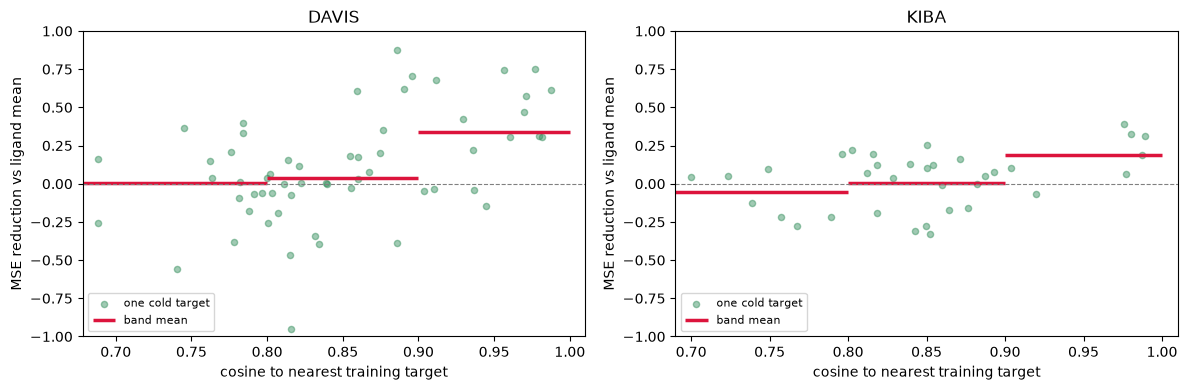

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, frame) in zip(axes, frames.items()):
    table = frame.per_target
    lo = table["near"].min() - 0.01
    ax.scatter(table["near"], 1 - table["kNN MSE"] / table["baseline MSE"],
               s=20, color="seagreen", alpha=0.45, label="one cold target")
    for band, group in table.groupby("band", observed=True):
        ax.hlines(group["relative drop"].mean(), max(band.left, lo), band.right,
                  color="crimson", linewidth=2.5,
                  label="band mean" if band.right == 0.8 else None)
    ax.set_xlim(lo, 1.01)
    ax.axhline(0.0, color="grey", linewidth=0.8, linestyle="--")
    ax.set_xlabel("cosine to nearest training target")
    ax.set_ylabel("MSE reduction vs ligand mean")
    ax.set_ylim(-1.0, 1.0)
    ax.set_title(name)
    ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("figures/task3_stratified.png", dpi=200)
plt.show()

The band means are still above 0 for all ranges, which indicated that the MSE is reduced and the method still improves cold-target generalisation, albeit very little in the first 2 bands. But there is only significant improvement above 0.9, so the method is most effective when 2 targets have a cosine similarity above this value.

Between DAVIES and KIBA, DAVIES has a greater proportion of cold targets in this value, which can explain why DAVIES scores, like MSE falling more, improved in the stats earlier.

### Comparing 2 extreme cases

The DAVIS cold target with the closest training relative,
and the one with the most distant.

In [138]:
def case_report(name, target_col):
    frame = frames[name]
    rows, cols, y_true = frame.xy("test")
    picked = np.flatnonzero(cols == target_col)
    predicted = models[name]["sequence kNN"].predict(rows[picked], cols[picked])
    table = (pd.DataFrame({"ligand": frame.ligands[rows[picked]],
                           "predicted": predicted, "true": y_true[picked]})
             .sort_values("predicted", ascending=False, kind="stable")
             .reset_index(drop=True))
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    table["label"] = np.where(table["true"] == table["true"].max(), "correct", "wrong")
    best_rank = int(table.loc[table["true"].idxmax(), "rank"])
    return table, best_rank


frame = frames["DAVIS"]
train_cols, test_cols = train_targets(frame), np.unique(frame.xy("test")[1])
nearest = (target_features["DAVIS"][test_cols]
           @ target_features["DAVIS"][train_cols].T)

for label, position in [("closest relative", nearest.max(axis=1).argmax()),
                        ("most distant", nearest.max(axis=1).argmin())]:
    target_col = test_cols[position]
    neighbour = frame.targets[train_cols[nearest[position].argmax()]]
    table, best_rank = case_report("DAVIS", target_col)
    print(f"=== {frame.targets[target_col]} ({label}): nearest training target "
          f"{neighbour} at cosine {nearest[position].max():.2f}; "
          f"true best ligand ranked {best_rank} of {len(table)} ===")
    print(table.head(8).round(3).to_string(index=False))
    print()

=== PKAC-beta (closest relative): nearest training target PKAC-alpha at cosine 0.99; true best ligand ranked 3 of 68 ===
 rank   ligand  predicted  true   label
    1    44259      7.353 7.538   wrong
    2   126565      6.420 6.796   wrong
    3 16725726      6.393 7.886 correct
    4 11314340      6.227 7.046   wrong
    5 16038120      5.866 5.387   wrong
    6 11984591      5.786 6.292   wrong
    7 51004351      5.699 6.620   wrong
    8  9809715      5.562 5.000   wrong

=== NLK (most distant): nearest training target MAP3K1 at cosine 0.69; true best ligand ranked 63 of 68 ===
 rank   ligand  predicted  true label
    1    44259      7.129 6.658 wrong
    2   126565      6.916 6.114 wrong
    3 11314340      6.540 5.000 wrong
    4 11427553      6.094 5.000 wrong
    5  5329102      6.086 5.000 wrong
    6 25243800      5.981 6.319 wrong
    7 11984591      5.879 5.000 wrong
    8 11409972      5.865 6.796 wrong



## 7. Conclusion

Task 2's recommender cannot serve a target with no training measurements: all of its
cold-target predictions are fallbacks, constant across a ligand's unseen targets, so its
per-ligand ranking reflects list order rather than any ability to rank.

Replacing co-measurement similarity with amino-acid sequence similarity restores the
capability with one hyperparameter and no fitted model. Test MSE falls from 0.460 to 0.370 on
DAVIS and 0.394 to 0.382 on KIBA, while per-ligand Hit@1 rises from 0.044 to 0.324 and from
0.077 to 0.260 against random references of 0.017 and 0.074.

The method works conditionally, and the condition is measurable: it adds nothing when the
nearest training relative is below cosine 0.8 and up to 37% MSE reduction above 0.9. Below 0.8, it falls
back to the ligand mean.

### Limitations

1. On KIBA the predicted scores are heavily smoothed (spread 0.06 against a true 0.48):
   the ranking is usable, but the predicted affinities are not accurate.
2. Ligands are never unseen in this split. A new drug and a new target together means that there are no usable neighbours and the method cannot be used.